# 03 · Modeling and evaluation

This notebook presents the results of `scripts/train.py` (read from `reports/`, so it runs in seconds).

**Evaluation protocol**

1. Stratified 80/20 split. The **test set is used once**, at the end.
2. **Pipeline selection:** 5-fold CV on the training set over 3 outlier strategies × 4 scalers × 4 resamplers
   (48 pipelines). All steps, including Boruta and oversampling, are refitted inside each fold.
3. **Hyperparameter tuning** of the Random Forest for the selected pipeline (same folds, 36 settings).
4. **Decision threshold** chosen from out-of-fold predictions on the training set.
5. **Final test evaluation**, with bootstrap confidence intervals.

Every choice is scored by the business cost: **100 per false alarm, 400 per missed failure.**

> **What changed from the original course project:** the original notebooks chose the pipeline by its cost on the
> test set, and oversampled the data before cross-validation. Both make results look better than they are.
> The numbers below are leak-free, and lower.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image

from secom.config import COST_FN, CV_FOLDS, FIGURES_DIR, REPORTS_DIR

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
results = json.loads((REPORTS_DIR / "results.json").read_text())
comparison = pd.read_csv(REPORTS_DIR / "cv_pipeline_comparison.csv")
oof = pd.read_csv(REPORTS_DIR / "oof_predictions.csv")
test_pred = pd.read_csv(REPORTS_DIR / "test_predictions.csv")

# cost of the simplest policy, "never flag a wafer", per CV fold
FLAG_NOTHING_FOLD = oof["fail"].sum() / CV_FOLDS * COST_FN
print(f"Flag-nothing cost per CV fold: {FLAG_NOTHING_FOLD:,.0f}")

Flag-nothing cost per CV fold: 6,640


## 1. Which preprocessing pipeline?

Mean cost per validation fold (lower is better). The dashed line is the cost of never flagging any wafer.

In [2]:
cols = ["outlier", "scaler", "resampler", "cost_mean", "cost_std", "roc_auc_mean", "recall_mean", "precision_mean"]
comparison[cols].head(10)

,outlier,scaler,resampler,cost_mean,cost_std,roc_auc_mean,recall_mean,precision_mean
0,none,robust,rose,7100.0,952.890,0.693,0.166,0.151
1,none,maxabs,rose,7140.0,958.332,0.679,0.166,0.157
2,none,minmax,rose,7140.0,1032.666,0.667,0.190,0.157
3,clip_bound,maxabs,rose,7160.0,640.625,0.701,0.373,0.166
4,none,standard,rose,7220.0,1070.327,0.683,0.119,0.129
5,clip_bound,standard,rose,7460.0,793.977,0.705,0.335,0.149
6,clip_nan,standard,none,7540.0,720.000,0.650,0.371,0.149
7,clip_bound,robust,rose,7640.0,773.563,0.710,0.324,0.139
8,clip_bound,standard,none,7640.0,691.665,0.662,0.348,0.145
9,clip_bound,robust,none,7660.0,776.144,0.676,0.372,0.147


,cost_mean,roc_auc_mean,recall_mean
resampler,,,
rose,7568.333,0.689,0.273
none,7838.333,0.665,0.348
smote,8105.000,0.671,0.423
adasyn,8626.667,0.669,0.442


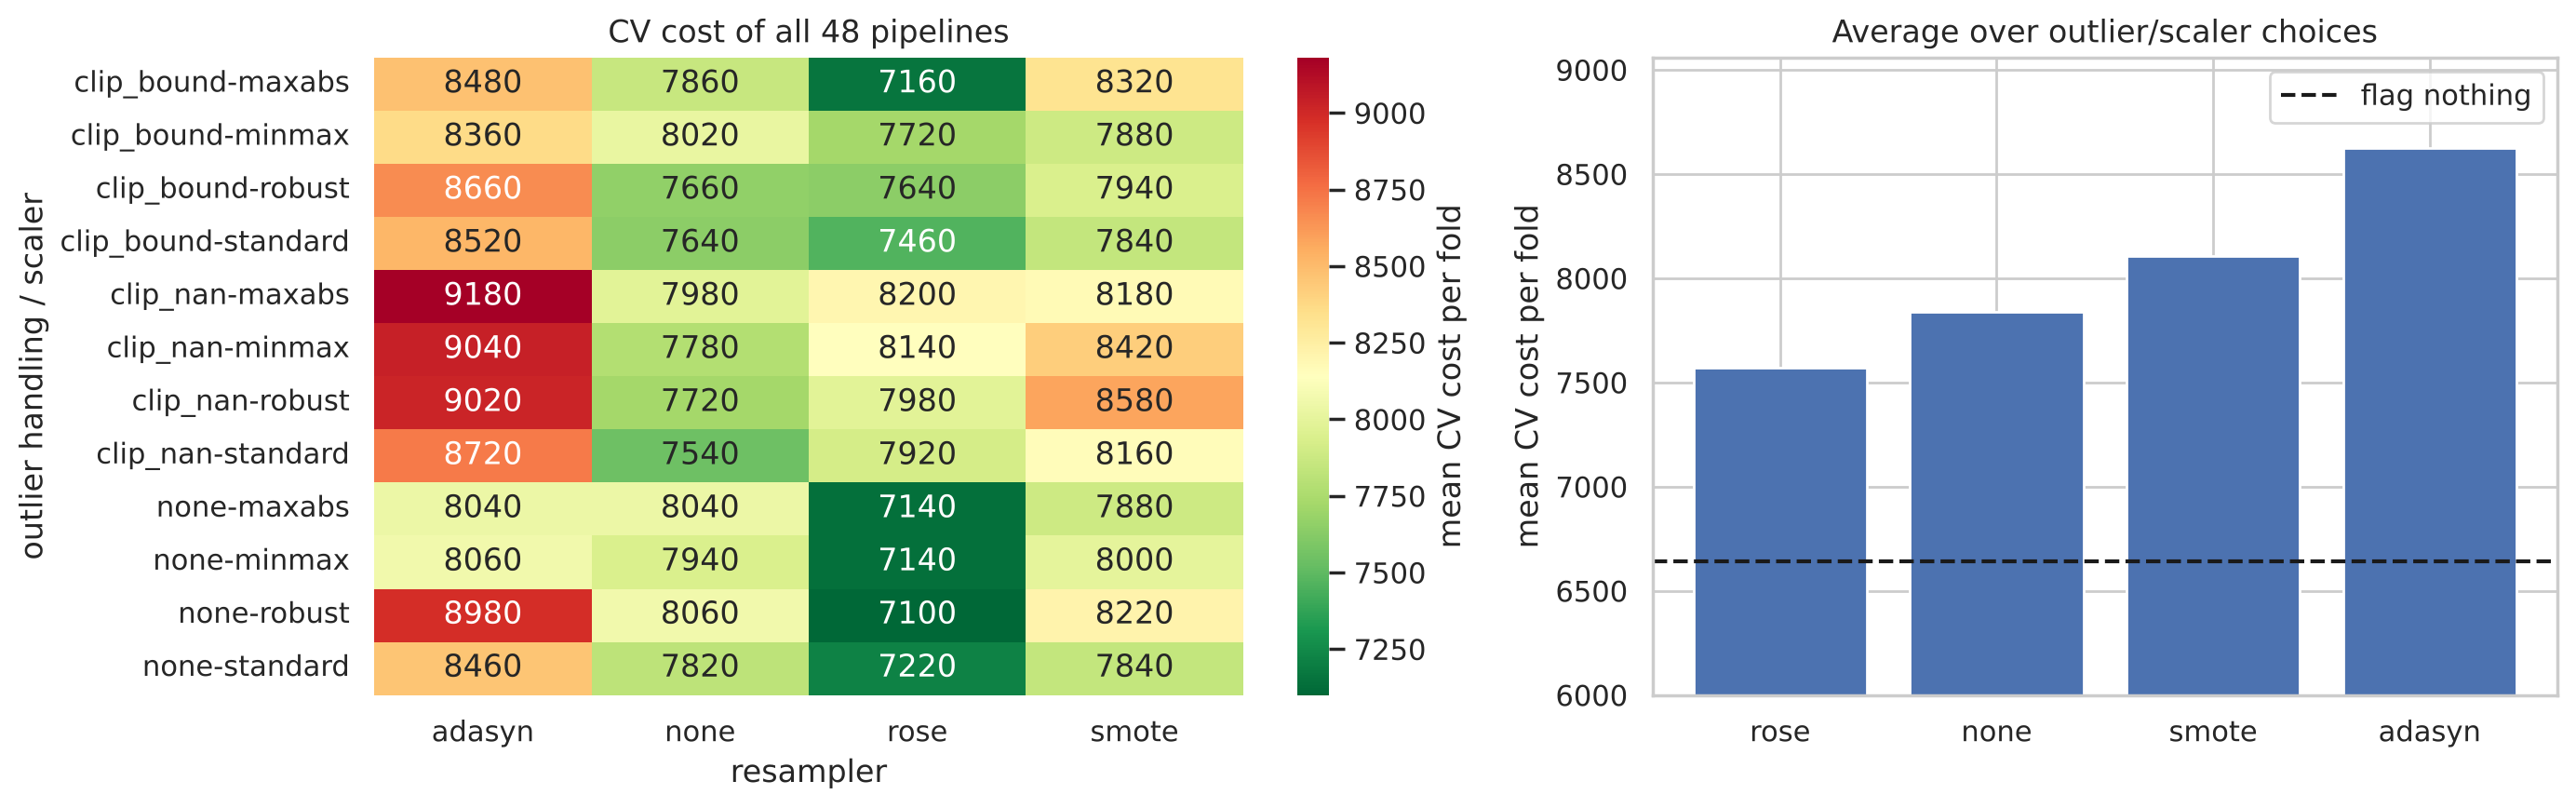

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
heat = comparison.pivot_table(index=["outlier", "scaler"], columns="resampler", values="cost_mean")
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdYlGn_r", ax=axes[0], cbar_kws={"label": "mean CV cost per fold"})
axes[0].set(title="CV cost of all 48 pipelines", xlabel="resampler", ylabel="outlier handling / scaler")

by_res = comparison.groupby("resampler")[["cost_mean", "roc_auc_mean", "recall_mean"]].mean().sort_values("cost_mean")
axes[1].bar(by_res.index, by_res["cost_mean"], color="#4C72B0")
axes[1].axhline(FLAG_NOTHING_FOLD, color="k", ls="--", label="flag nothing")
axes[1].set(title="Average over outlier/scaler choices", ylabel="mean CV cost per fold", ylim=(6000, None))
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "cv_pipeline_comparison.png", dpi=150)
by_res

- **ROSE** gives the lowest average cost and the highest ROC-AUC, so it is the best resampler.
  SMOTE and ADASYN catch more failures but raise so many false alarms that their cost goes up.
- The best pipeline (`none / robust / ROSE`) wins by a margin far smaller than the fold-to-fold standard
  deviation (≈ 700–1,000). **The choice of outlier strategy and scaler barely matters.**
- At the default 0.5 threshold, **no pipeline beats "flag nothing"** in cross-validation. That is the
  first sign that, at a 4:1 cost ratio, the available signal is weak.

## 2. Hyperparameter tuning

In [4]:
tuning = pd.read_csv(REPORTS_DIR / "cv_tuning.csv")
params = [c for c in tuning if c.startswith("param_")]
top = tuning.sort_values("rank_test_cost")[
    params + ["mean_test_cost", "std_test_cost", "mean_test_roc_auc", "mean_test_recall"]
]
top = top.assign(mean_test_cost=-top["mean_test_cost"]).rename(
    columns=lambda c: c.replace("param_model__", "").replace("mean_test_", "cv_")
)
top.head(8)

,class_weight,max_depth,min_samples_leaf,n_estimators,cv_cost,std_test_cost,cv_roc_auc,cv_recall
12,balanced,NaN,1,100,6720.0,1068.457,0.662,0.191
11,balanced,10.0,4,400,6740.0,900.222,0.681,0.178
17,balanced,NaN,4,400,6740.0,1040.385,0.675,0.203
9,balanced,10.0,4,100,6780.0,847.113,0.680,0.178
14,balanced,NaN,1,400,6780.0,1177.115,0.675,0.180
15,balanced,NaN,4,100,6780.0,982.649,0.670,0.202
29,NaN,10.0,4,400,6780.0,711.056,0.681,0.167
10,balanced,10.0,4,200,6780.0,881.816,0.680,0.178


## 3. Decision threshold

A wafer is flagged when its predicted failure probability exceeds a threshold. The threshold is chosen to
minimise cost on **out-of-fold** predictions for the training set, never on test data.

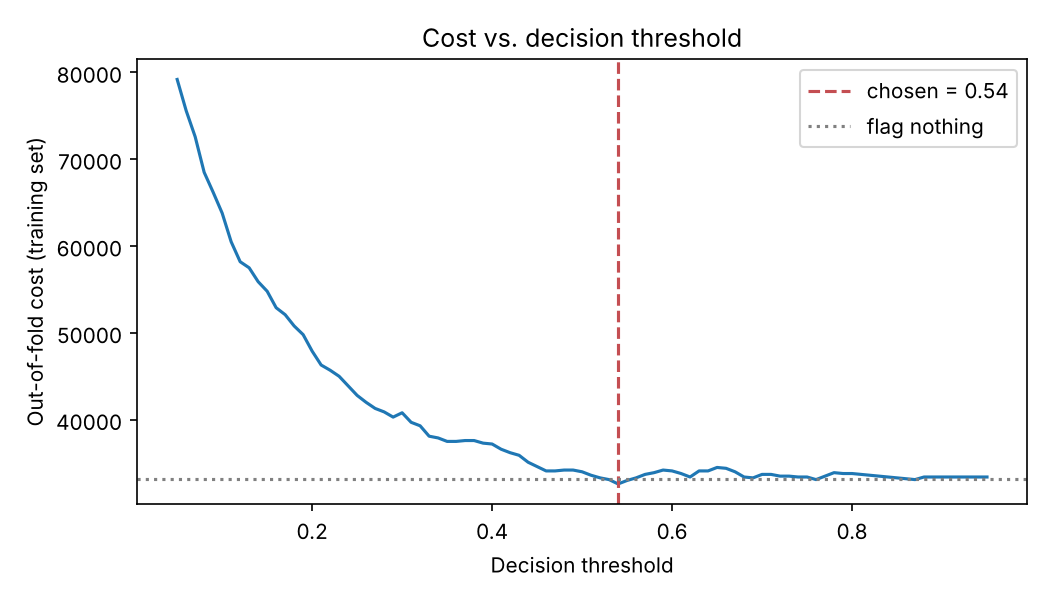

In [5]:
Image(FIGURES_DIR / "threshold_cost_curve.png", width=650)

In [6]:
flag_nothing_train = oof["fail"].sum() * COST_FN
curve = pd.read_csv(REPORTS_DIR / "cv_threshold_curve.csv")
print(f"chosen threshold: {results['threshold']}")
print(f"out-of-fold cost at that threshold: {curve['cost'].min():,.0f}  vs. flag nothing: {flag_nothing_train:,.0f}")

chosen threshold: 0.54
out-of-fold cost at that threshold: 32,600  vs. flag nothing: 33,200


The ROSE-trained model is fitted on a 50/50 class balance, so its probabilities are inflated; the cost
optimum therefore sits near 0.5 instead of the textbook `100 / (100 + 400) = 0.2`. Out of fold, the best
threshold saves only about 2 % against flagging nothing.

## 4. Test-set results

In [7]:
test = pd.read_csv(REPORTS_DIR / "test_metrics.csv")
test[["model", "threshold", "recall", "precision", "specificity", "f1", "roc_auc", "tp", "fp", "fn", "cost"]]

,model,threshold,recall,precision,specificity,f1,roc_auc,tp,fp,fn,cost
0,Flag nothing,NaN,0.000,0.000,1.000,0.000,0.500,0,0,21,8400.0
1,Baseline (no resampling),0.50,0.238,0.106,0.857,0.147,0.702,5,42,16,10600.0
2,Selected pipeline (ROSE),0.50,0.238,0.385,0.973,0.294,0.665,5,8,16,7200.0
3,Tuned,0.50,0.286,0.375,0.966,0.324,0.695,6,10,15,7000.0
4,Tuned + cost threshold,0.54,0.238,0.455,0.980,0.312,0.695,5,6,16,7000.0


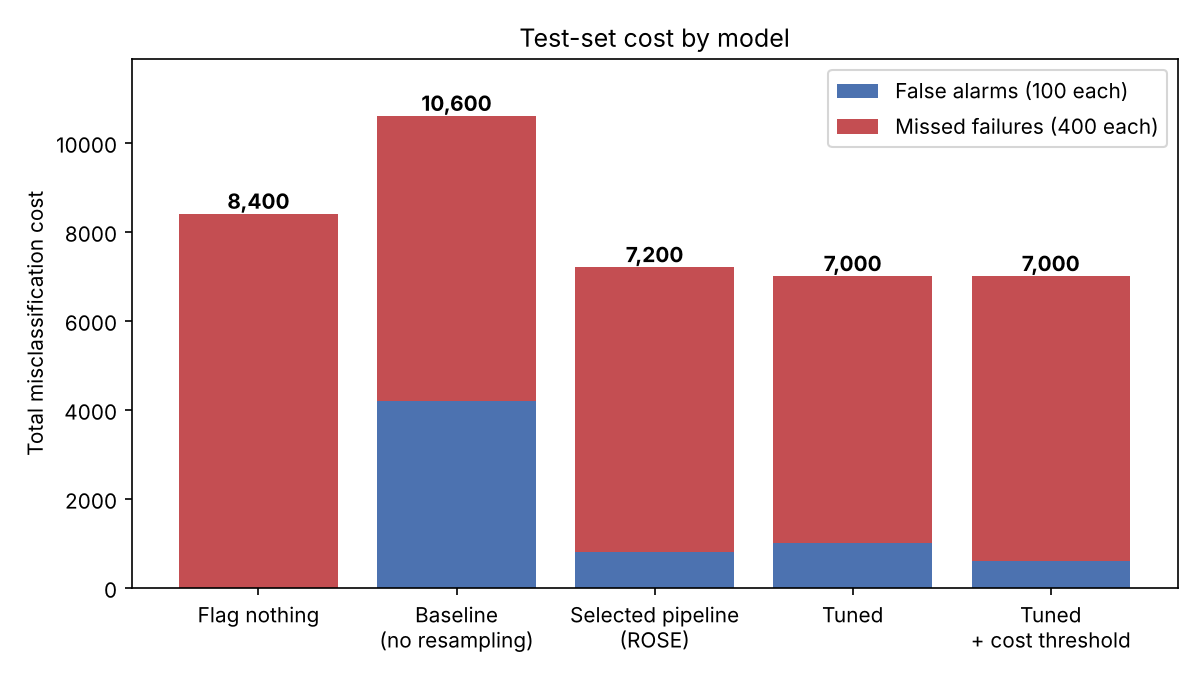

In [8]:
Image(FIGURES_DIR / "test_cost_breakdown.png", width=700)

In [9]:
ci = pd.read_csv(REPORTS_DIR / "test_bootstrap_ci.csv", index_col=0)
final = test.set_index("model").loc["Tuned + cost threshold"]
ci.insert(0, "estimate", final[ci.index].astype(float))
ci  # 95 % bootstrap intervals, final model

,estimate,ci_low,ci_high
recall,0.238,0.077,0.440
precision,0.455,0.167,0.778
f1,0.312,0.100,0.513
roc_auc,0.695,0.574,0.813
cost,7000.000,4000.000,10400.000


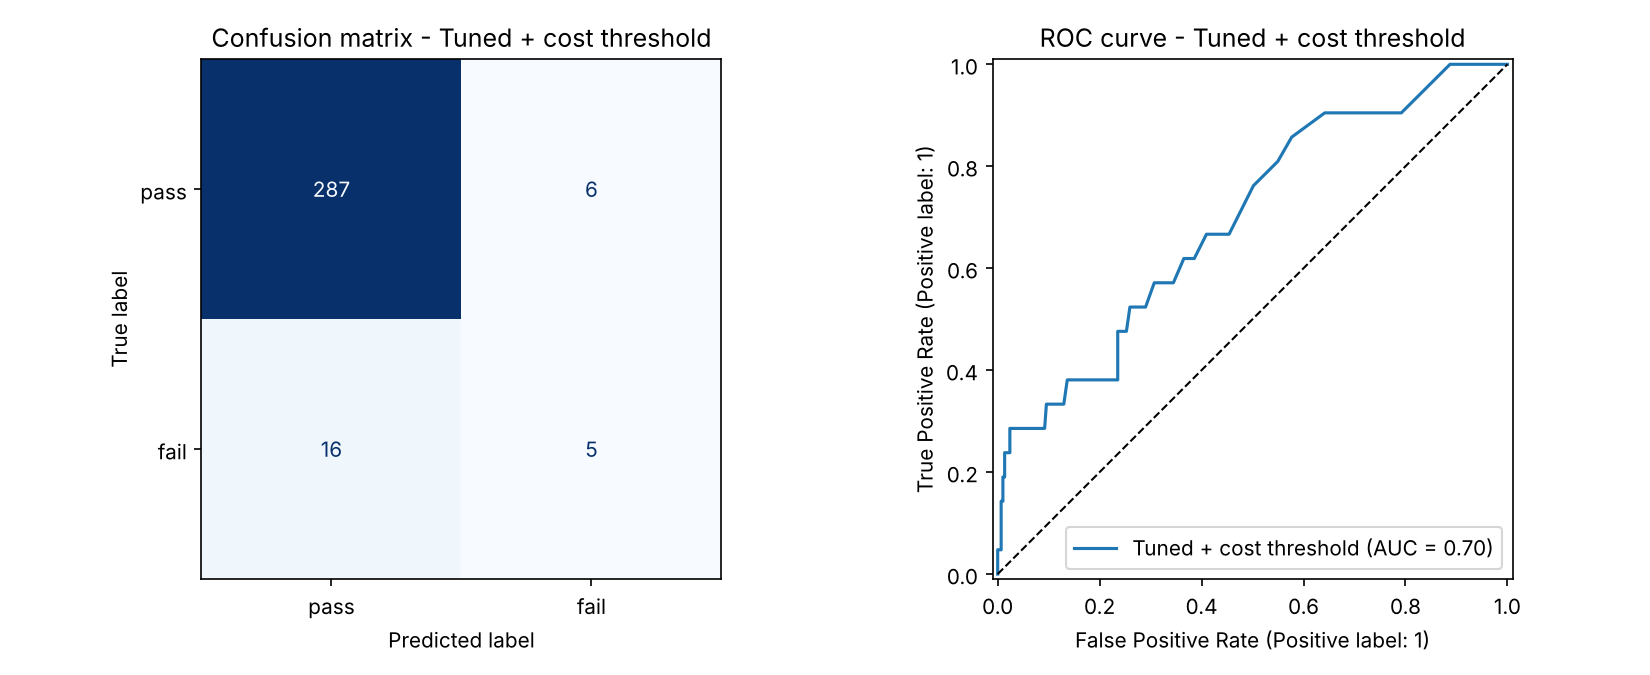

In [10]:
Image(FIGURES_DIR / "final_confusion_roc.png", width=850)

On the test set the final model flags 11 of 314 wafers, catches 5 of the 21 failures and costs **7,000 vs.
8,400** for flagging nothing (−17 %). With only 21 test failures, however, the 95 % interval for the cost
(4,000–10,400) still contains 8,400. The ROC-AUC of 0.70 (CI 0.57–0.81) shows a **real but weak signal**.

## 5. When does the model pay off?

The 4:1 cost ratio is an assumption. The chart below repeats the threshold choice for other ratios
(out-of-fold, training set) and compares the model with the **best no-model rule**: flag nothing, or
inspect every wafer when misses are very expensive.

,missed failure / false alarm,threshold,saving (CV),saving (test)
0,2,1.00,0.000,0.000
1,3,0.87,0.000,0.048
2,4,0.54,0.018,0.167
3,6,0.54,0.072,0.190
4,8,0.46,0.107,0.202
5,10,0.29,0.160,0.171
6,15,0.12,0.230,0.195
7,20,0.03,0.126,0.160


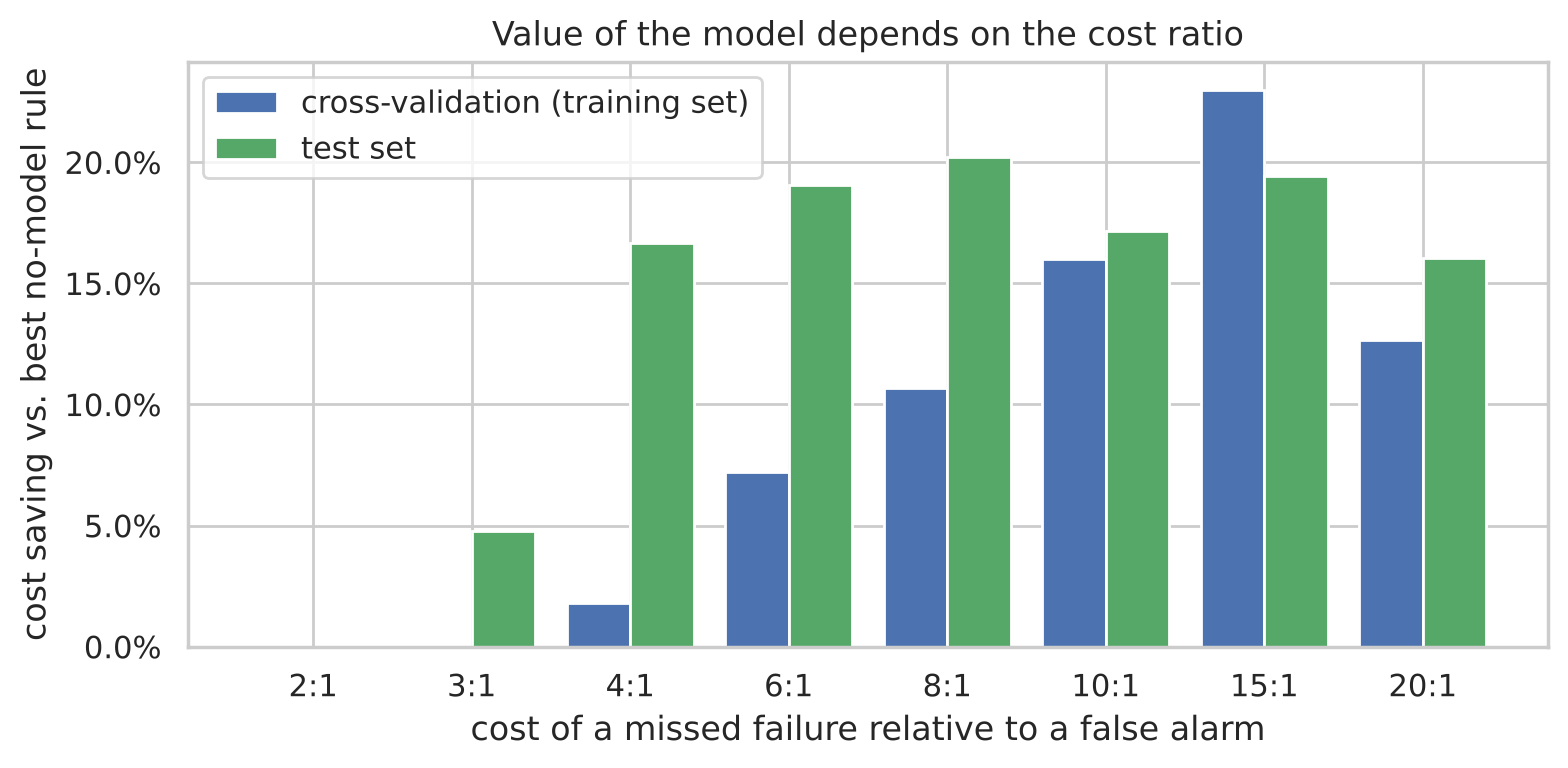

In [11]:
grid = np.round(np.arange(0, 1.001, 0.01), 2)


def cost(y, p, t, ratio):  # in units of one false alarm
    flag = p >= t
    return ((flag) & (y == 0)).sum() + ratio * ((~flag) & (y == 1)).sum()


def no_model_cost(y, ratio):
    return min(ratio * (y == 1).sum(), (y == 0).sum())


rows = []
for ratio in [2, 3, 4, 6, 8, 10, 15, 20]:
    t = grid[np.argmin([cost(oof["fail"], oof["proba"], t, ratio) for t in grid])]
    rows.append(
        {
            "missed failure / false alarm": ratio,
            "threshold": t,
            "saving (CV)": 1 - cost(oof["fail"], oof["proba"], t, ratio) / no_model_cost(oof["fail"], ratio),
            "saving (test)": 1
            - cost(test_pred["fail"], test_pred["proba"], t, ratio) / no_model_cost(test_pred["fail"], ratio),
        }
    )
sens = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(sens))
ax.bar(x - 0.2, sens["saving (CV)"], 0.4, label="cross-validation (training set)", color="#4C72B0")
ax.bar(x + 0.2, sens["saving (test)"], 0.4, label="test set", color="#55A868")
ax.set_xticks(x, [f"{r}:1" for r in sens["missed failure / false alarm"]])
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(
    xlabel="cost of a missed failure relative to a false alarm",
    ylabel="cost saving vs. best no-model rule",
    title="Value of the model depends on the cost ratio",
)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "cost_ratio_sensitivity.png", dpi=150)
sens

In cross-validation the model is worth little at 4:1 (≈ 2 % saving) but becomes useful once a missed
failure costs **around 6–15× a false alarm** (≈ 7–23 % saving). Pinning down the real cost ratio with the
fab is the most important question before any deployment.

## 6. Which sensors matter?

Boruta: 450 sensors -> 15 confirmed, 3 tentative


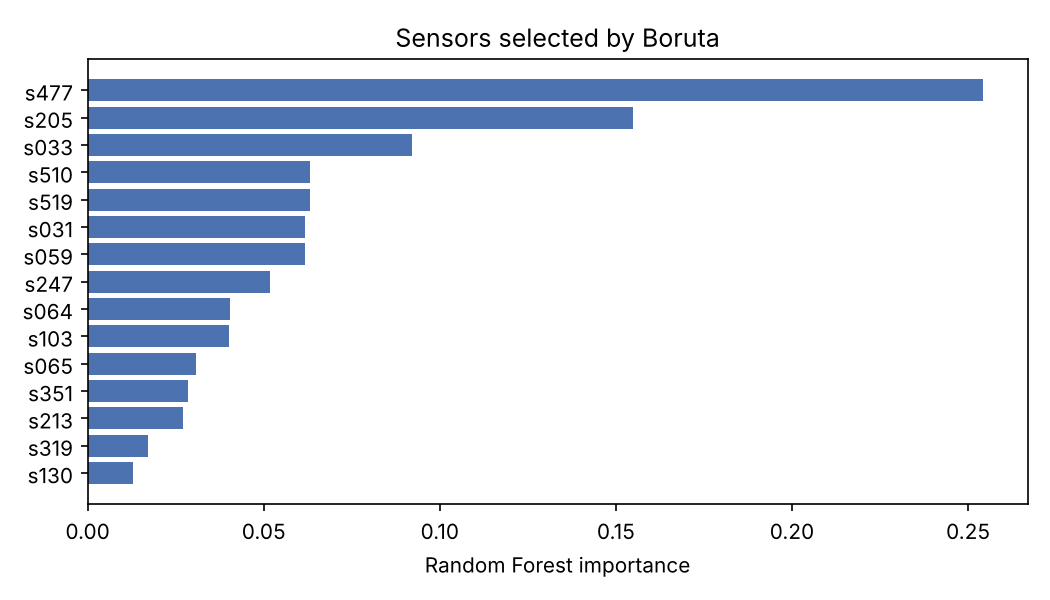

In [12]:
sensors = pd.read_csv(REPORTS_DIR / "selected_sensors.csv")
print(
    f"Boruta: 450 sensors -> {(sensors.boruta_status == 'confirmed').sum()} confirmed, "
    f"{(sensors.boruta_status == 'tentative').sum()} tentative"
)
Image(FIGURES_DIR / "feature_importance.png", width=650)

These sensors are **associated** with failure; the data cannot say whether they measure the cause or
are simply drifting instruments. The list is a starting point for process engineers, not a root-cause finding.

## 7. Comparison with the original course results

| | Original notebooks | This repository (leak-free) |
|---|---|---|
| Pipeline chosen by | cost on the **test set** | 5-fold CV on the training set |
| Oversampling before CV | yes (inflates CV scores) | no, inside each fold |
| Selected pipeline | 3σ capping / Standard / ROSE | none / Robust / ROSE |
| Selected sensors | 10 (+4 tentative) | 15 (+3 tentative) |
| Test ROC-AUC | 0.779 | 0.695 |
| Test recall | 0.429 | 0.238 |
| Test cost (flag nothing = 8,400) | 7,000 | 7,000 |

The original pipeline was effectively tuned on the data it was scored on, so its ROC-AUC and recall were
optimistic. The cost figure comes out similar, but here it is an honest estimate with a wide interval.

## 8. Conclusions

1. **There is a predictive signal** in the sensor data (ROC-AUC ≈ 0.70), concentrated in about 15 sensors.
2. **At a 4:1 cost ratio the model barely beats flagging nothing**; it becomes valuable when a missed failure
   costs roughly 6–15× a false alarm.
3. **Preprocessing choices matter less than the evaluation protocol.** Most of the difference between the
   course results and these comes from removing test-set leakage, not from modeling changes.
4. The model is suited, at best, to **triage** (pick wafers for extra inspection), not to replace the final test.

**Next steps:** time-based validation (the failure rate drifts strongly over the recording period), probability
calibration, gradient boosting and logistic-regression baselines, and confirming the real cost ratio with domain experts.